# $\pi/\sqrt{3}-\log3$, $\pi/\sqrt{3}+\log3$: historical CMF bounds

Hata's (1992) approximants at source index 1000. Finite-depth exponents do not prove the published bounds. 


In [ ]:
# @title Install dependencies (run once per environment)
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 python-flint matplotlib==3.11.2


## Setup

Put $F={}_2F_1(1,1-d;2-d;1/s)$ and $m=\lfloor n/\lambda\rfloor$.
Hata's integration by parts (p. 346) gives
$$J_j(U,V,W)=\int_0^1\frac{t^{U+j}(1-t)^V}{(1-t/s)^W}\,dt,\quad j=0,1,$$
at $(U,V,W)=(n-d,n+m,n+1)$.
Euler integration gives $J_0=B(U+1,V+1){}_2F_1(W,U+1;U+V+2;1/s)$.
We construct this rank-2 CMF directly with `pFq(2, 1, 1/s)`.
At $(1,1-d;2-d)$ the $(F,\theta F)$ state has coefficient rows
$$C=(0,s/(s-1)),\qquad B=(1/(1-d),-1),$$
up to a common scalar. For target $\alpha=cF$, transport these rows and read
$p_n/q_n=-c(CM)_0/(BM)_0$; the beta normalization cancels.


In [1]:
import matplotlib.pyplot as plt
import sympy as sp
from flint import arb, ctx
from ramanujantools import Matrix
from ramanujantools.cmf.pfq import pFq

x0, x1, y0 = sp.symbols("x0 x1 y0")
results = {}


def delta(r, target):
    """Reduced rational exponent, evaluated with a positive interval error."""
    p, q = int(r.p), int(r.q)
    with ctx.workprec(2*q.bit_length()+256):
        error = abs(target()-arb(p)/q)
        assert error > 0
        value = -1-error.log()/arb(q).log()
        assert value.is_finite() and value.rad() < arb("1e-18")
        return float(value.mid())


## 1. Hata (1992): $\pi/\sqrt{3}-\log3$

[Theorem 1.2, Theorem 3.1 and Eq. (3.10)](https://matwbn.icm.edu.pl/ksiazki/aa/aa60/aa6043.pdf). Published bound: $\mu(\alpha)\le 4.5586217\ldots$.

Parameters $(d,s,\lambda)=(1/3,-8,3)$; target multiplier $c=3/4$.
**CMF:** rank 2, ${}_2F_1(1/s)$; **start:** $(2,2-d;4-d)$, reached from $(1,1-d;2-d)$; **direction:** $(\lambda,\lambda;2\lambda+1)$.
After $k$ steps, $n=1+3k$ and $m=k$, so $k=333$ gives exactly $n=1000$.


In [2]:
d, s, lam, scale = sp.Rational("1/3"), -8, 3, sp.Rational("3/4")
cmf = pFq(2, 1, sp.Rational(1, s))
seed = {x0: 1, x1: 1-d, y0: 2-d}
start = {x0: 2, x1: 2-d, y0: 4-d}
C = Matrix([[0, sp.Rational(s, s-1)]])
B = Matrix([[1/(1-d), -1]])
T = cmf.work(seed, start)
C, B = C*T, B*T
trajectory = {x0: lam, x1: lam, y0: 2*lam+1}
periods = [k for k in range(334) if 1+lam*k >= 10 and (k % 3 == 0 or 1+lam*k == 1000)]
depths = [1+lam*k for k in periods]
walks = cmf.walk(trajectory, periods, start)
approximants = [-scale*(C*M)[0]/(B*M)[0] for M in walks]
target = lambda: arb.pi()/arb(3).sqrt()-arb(3).log()
deltas = [delta(r, target) for r in approximants]
results['$\\pi/\\sqrt{3}-\\log3$'] = (depths, deltas)
print(f"delta at source depth 1000: {deltas[-1]:.12f}")


delta at source depth 1000: 0.286085634604


## 2. Hata (1992): $\pi/\sqrt{3}+\log3$

[Theorem 1.2, Theorem 3.1 and Eq. (3.10)](https://matwbn.icm.edu.pl/ksiazki/aa/aa60/aa6043.pdf). Published bound: $\mu(\alpha)\le 4.5586217\ldots$.

Parameters $(d,s,\lambda)=(2/3,-8,3)$; target multiplier $c=3$.
**CMF:** rank 2, ${}_2F_1(1/s)$; **start:** $(2,2-d;4-d)$, reached from $(1,1-d;2-d)$; **direction:** $(\lambda,\lambda;2\lambda+1)$.
After $k$ steps, $n=1+3k$ and $m=k$, so $k=333$ gives exactly $n=1000$.


In [3]:
d, s, lam, scale = sp.Rational("2/3"), -8, 3, sp.Rational("3")
cmf = pFq(2, 1, sp.Rational(1, s))
seed = {x0: 1, x1: 1-d, y0: 2-d}
start = {x0: 2, x1: 2-d, y0: 4-d}
C = Matrix([[0, sp.Rational(s, s-1)]])
B = Matrix([[1/(1-d), -1]])
T = cmf.work(seed, start)
C, B = C*T, B*T
trajectory = {x0: lam, x1: lam, y0: 2*lam+1}
periods = [k for k in range(334) if 1+lam*k >= 10 and (k % 3 == 0 or 1+lam*k == 1000)]
depths = [1+lam*k for k in periods]
walks = cmf.walk(trajectory, periods, start)
approximants = [-scale*(C*M)[0]/(B*M)[0] for M in walks]
target = lambda: arb.pi()/arb(3).sqrt()+arb(3).log()
deltas = [delta(r, target) for r in approximants]
results['$\\pi/\\sqrt{3}+\\log3$'] = (depths, deltas)
print(f"delta at source depth 1000: {deltas[-1]:.12f}")


delta at source depth 1000: 0.286239222720


## All constructions

$\delta_N$ against source index $N$.


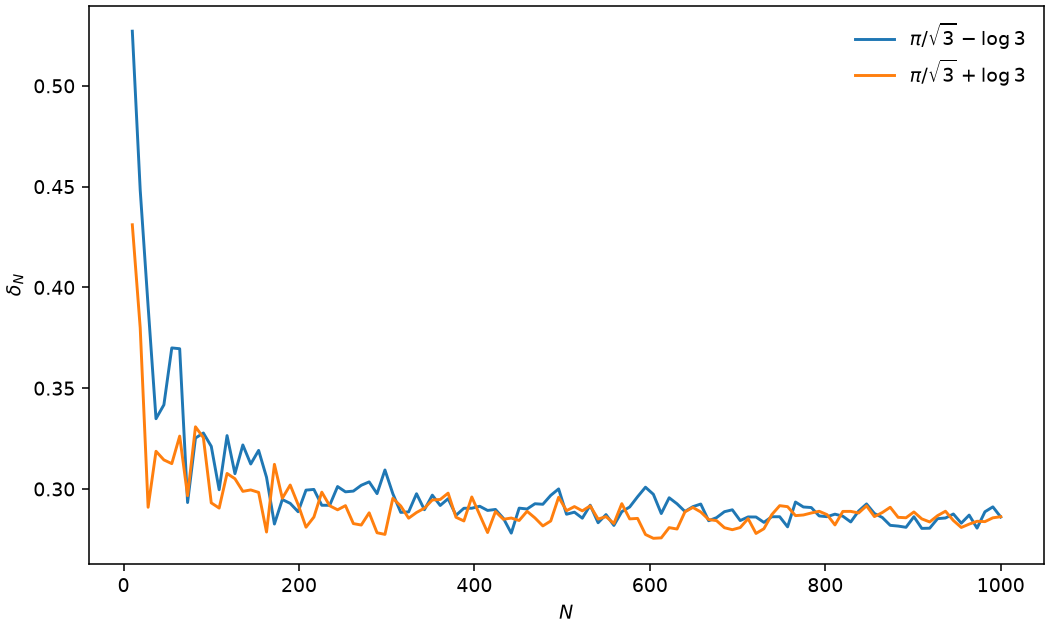

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 4.5), constrained_layout=True)
for name, (depths, values) in results.items():
    ax.plot(depths, values, label=name)
ax.set(xlabel="$N$", ylabel=r"$\delta_N$")
ax.legend(frameon=False)
plt.show()


## Historical overview

| Target (Hata 1992) | Published bound | $\delta_{\rm eq}$ (approx.) | $\delta_{1000}$ |
|:--|--:|--:|--:|
| $\pi/\sqrt{3}-\log3$ | 4.5586217... | 0.28100767 | 0.286085634604 |
| $\pi/\sqrt{3}+\log3$ | 4.5586217... | 0.28100767 | 0.286239222720 |

$\delta_{\rm eq}=1/(\mu_0-1)$. The source's arithmetic and asymptotic proofs are not independently reproved here.

The script local_checks/verify_hata_hypergeometric.py checks the target identities and both coefficient rows against Hata's polynomial (1.2) and rational integral on p. 344 for $n=0,\ldots,6$. The file local_checks/hata_hypergeometric_checks.json records these checks and the depth-1000 interval verification at two precisions.
